In [ ]:
## 1.  성남시의 고령화 현황 파악
## 2. 고령자 소비환경 분석
## 3. 고령자 복지 이용 현황
## 4. 고령자 이동/접근성 문제 파악
## 5. 사회적 고립/여가활동 부족
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
plt.rcParams['font.family']= 'NanumGothic' 
plt.rcParams['axes.unicode_minus']=False

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 파일 경로 목록
file_paths = [
    "경기도 성남시_1인가구_현황_20200531.csv",
    "경기도 성남시_1인가구_현황_20210430.csv",
    "경기도 성남시_1인가구_현황_20240531.csv"
]

# 각 파일 읽기 및 연도 추가
dfs = []
for path in file_paths:
    df = pd.read_csv(path, encoding='cp949')
    
    # 파일명에서 날짜 추출하고 앞 4자리 = 연도로 사용
    filename = os.path.basename(path)
    date_part = filename.split('_')[-1].split('.')[0]  # _20001010.
    year = int(date_part[:4])  # 연도만 추출
    
    df['연도'] = year
    dfs.append(df)

# 데이터 결합
combined_df = pd.concat(dfs, ignore_index=True)

# 확인
print(combined_df[['연도']].drop_duplicates())
combined_df.head()



       연도
0    2020
50   2021
100  2024


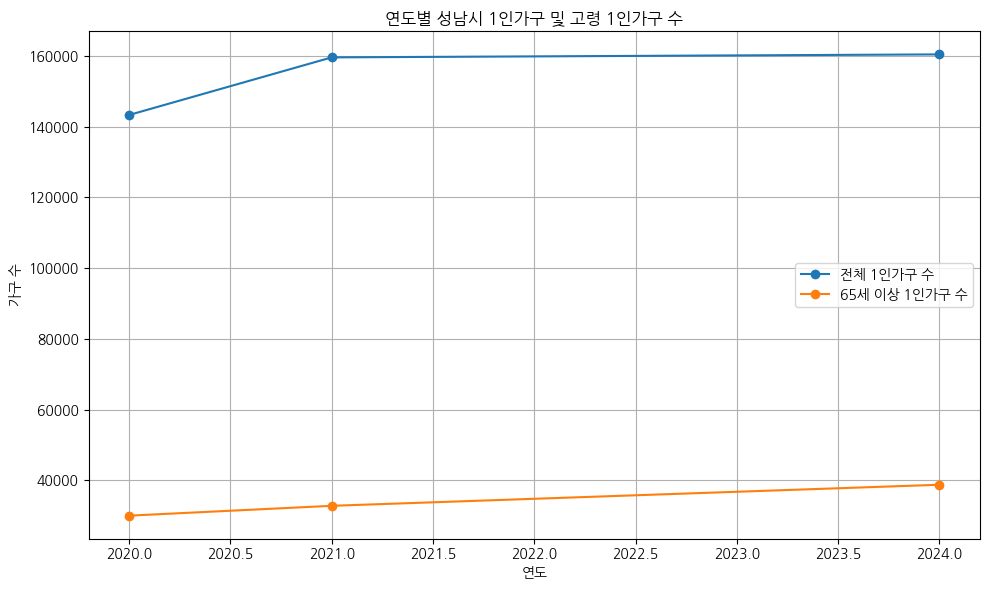

In [ ]:
# 연도별 전체 1인가구 수와 65세 이상 1인가구 수 집계
yearly_summary = combined_df.groupby('연도').agg({
    '1인가구수_계': 'sum',
    '65세 이상(계)': 'sum'
}).reset_index()

# 1. 전체 1인가구 수 & 65세 이상 1인가구 수 시각화
plt.figure(figsize=(10, 6))
plt.plot(yearly_summary['연도'], yearly_summary['1인가구수_계'], marker='o', label='전체 1인가구 수')
plt.plot(yearly_summary['연도'], yearly_summary['65세 이상(계)'], marker='o', label='65세 이상 1인가구 수')
plt.title('연도별 성남시 1인가구 및 고령 1인가구 수')
plt.xlabel('연도')
plt.ylabel('가구 수')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


### 20년도와 24년도만 비교: why? 2020년도에 코로나19로 변화의 발단?이 될만할 의미가 있다고 생각함.

In [ ]:
# 2020년과 2024년 데이터 필터링
df_2020 = combined_df[combined_df['연도'] == 2020]
df_2024 = combined_df[combined_df['연도'] == 2024]

# 구별 고령 1인가구 수 합계 비교
gu_comparison = pd.DataFrame({
    '2020년': df_2020.groupby('구별')['65세 이상(계)'].sum(),
    '2024년': df_2024.groupby('구별')['65세 이상(계)'].sum()
}).reset_index()

# 변화량 및 증가율 계산
gu_comparison['증가수'] = gu_comparison['2024년'] - gu_comparison['2020년']
gu_comparison['증가율(%)'] = (gu_comparison['증가수'] / gu_comparison['2020년']) * 100

# 결과 출력
print(gu_comparison)


    구별  2020년  2024년   증가수     증가율(%)
0  분당구  10953  13641  2688  24.541222
1  수정구  10374  13893  3519  33.921342
2  중원구   8694  11225  2531  29.112031


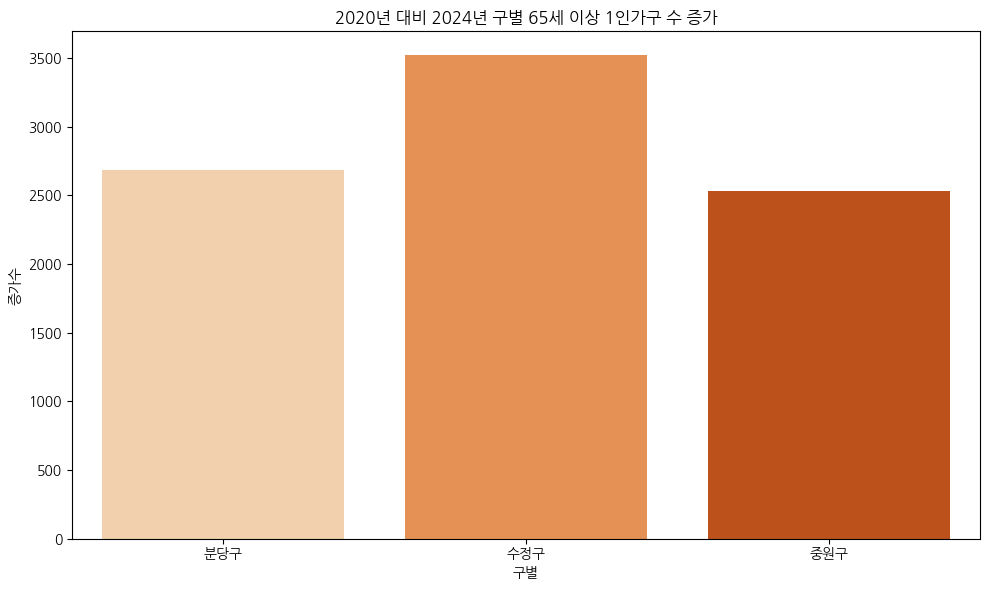

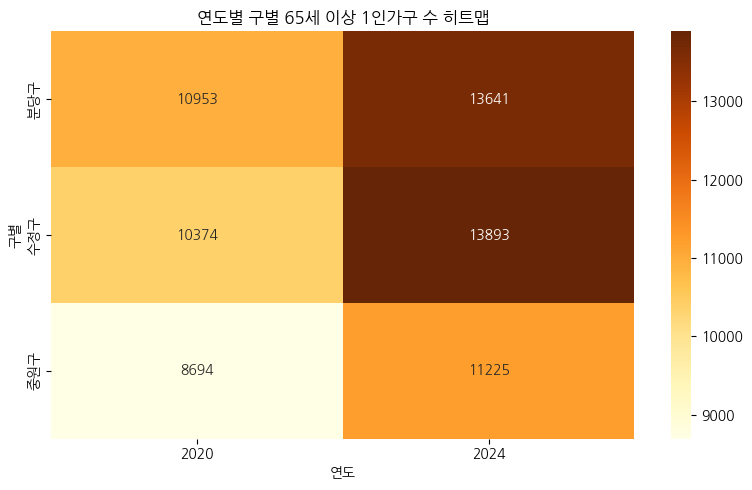

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 증가수 막대그래프
plt.figure(figsize=(10, 6))
sns.barplot(data=gu_comparison, x='구별', y='증가수', palette='Oranges')
plt.title('2020년 대비 2024년 구별 65세 이상 1인가구 수 증가')
plt.ylabel('증가수')
plt.xlabel('구별')
plt.tight_layout()
plt.show()

# 히트맵 (구별, 연도별 고령 1인가구 수)
heatmap_df = combined_df[combined_df['연도'].isin([2020, 2024])]
heatmap_pivot = heatmap_df.pivot_table(index='구별', columns='연도', values='65세 이상(계)', aggfunc='sum')

plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_pivot, annot=True, fmt=".0f", cmap="YlOrBr")
plt.title('연도별 구별 65세 이상 1인가구 수 히트맵')
plt.ylabel('구별')
plt.xlabel('연도')
plt.tight_layout()
plt.show()


In [ ]:
# 코로나 시작 2020년도
# 2020년과 2024년 데이터만 필터링
df_2020 = combined_df[combined_df['연도'] == 2020]
df_2024 = combined_df[combined_df['연도'] == 2024]

# 나이대별 컬럼 목록 지정
age_cols = [
    '60세-64세(계)',
    '65세 이상(계)'
]

# 나이대별 합계 계산
age_summary_2020 = df_2020[age_cols].sum().rename('2020년')
age_summary_2024 = df_2024[age_cols].sum().rename('2024년')

# 데이터프레임 병합
age_comparison = pd.concat([age_summary_2020, age_summary_2024], axis=1)
age_comparison['증가수'] = age_comparison['2024년'] - age_comparison['2020년']
age_comparison['증가율(%)'] = (age_comparison['증가수'] / age_comparison['2020년']) * 100


pd.set_option('display.float_format', '{:.2f}'.format)  # 소수점 정리
display(age_comparison)


In [ ]:
# 연령대 컬럼 목록 추출 (0세부터 65세 이상까지 포함된 컬럼)
age_columns = [col for col in df_2020.columns if '세' in col and '(계)' in col]

# 2020년, 2024년 나이대별 합계 계산
age_sum_2020 = df_2020[age_columns].sum().rename('2020년')
age_sum_2024 = df_2024[age_columns].sum().rename('2024년')

# 합치고 증가 수 및 증가율 계산
full_age_comparison = pd.concat([age_sum_2020, age_sum_2024], axis=1)
full_age_comparison['증가수'] = full_age_comparison['2024년'] - full_age_comparison['2020년']
full_age_comparison['증가율(%)'] = (full_age_comparison['증가수'] / full_age_comparison['2020년']) * 100

# 인덱스 정리
full_age_comparison.index.name = '연령대'

# 출력
full_age_comparison = full_age_comparison.reset_index()
full_age_comparison.sort_values('연령대', inplace=True)


pd.set_option('display.float_format', '{:.2f}'.format)  ## 소수ㅜ점
full_age_comparison


In [ ]:
# 연령대 컬럼 목록 자동 추출 (0세부터 65세 이상까지 포함된 컬럼)
age_columns = [col for col in df_2020.columns if '세' in col and '(계)' in col]

# 2020년, 2024년 나이대별 합계 계산
age_sum_2020 = df_2020[age_columns].sum().rename('2020년')
age_sum_2024 = df_2024[age_columns].sum().rename('2024년')

# 합치고 증가 수 및 증가율 계산
full_age_comparison = pd.concat([age_sum_2020, age_sum_2024], axis=1)
full_age_comparison['증가수'] = full_age_comparison['2024년'] - full_age_comparison['2020년']
full_age_comparison['증가율(%)'] = (full_age_comparison['증가수'] / full_age_comparison['2020년']) * 100

# 인덱스 정리
full_age_comparison.index.name = '연령대'

# 출력
full_age_comparison = full_age_comparison.reset_index()
full_age_comparison.sort_values('연령대', inplace=True)

pd.set_option('display.float_format', '{:.2f}'.format)
full_age_comparison
## 그래프로 시각화 필수

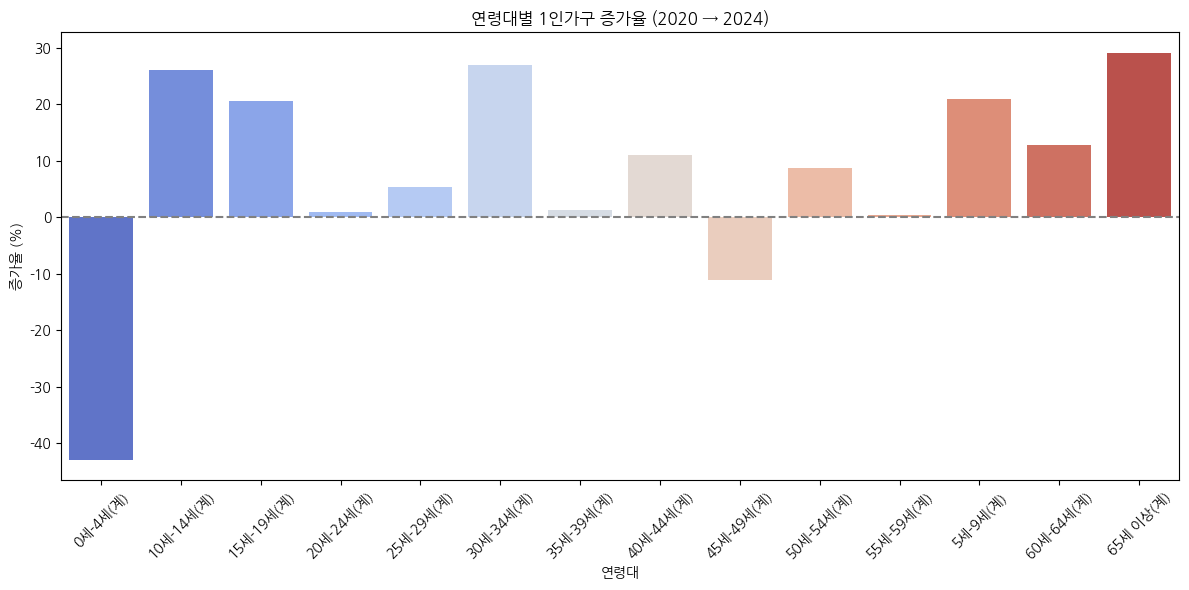

In [ ]:
# 연령대별 증가율 막대그래프
plt.figure(figsize=(12, 6))
sns.barplot(data=full_age_comparison, x='연령대', y='증가율(%)', palette='coolwarm')
plt.xticks(rotation=45)
plt.title('연령대별 1인가구 증가율 (2020 → 2024)')
plt.xlabel('연령대')
plt.ylabel('증가율 (%)')
plt.axhline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# 파일 경로 목록과 연도 매핑
population_files = {
    "2020": "경기도_성남시_2020년_11월_인구현황_20201201.csv",
    "2021": "경기도 성남시_인구및세대_현황_20211231.csv",
    "2022": "경기도 성남시_인구및세대_현황_20221231.csv",
    "2023": "경기도 성남시_인구및세대_현황_20231231.csv",
    "2024": "경기도 성남시_인구및세대_현황_20241231.csv",
    "2025": "경기도 성남시_인구및세대_현황_20250228.csv"
}

# 데이터프레임 리스트
population_dfs = []

# 파일 읽기
for year, path in population_files.items():
    try:
        df = pd.read_csv(path, encoding='cp949')
    except:
        df = pd.read_csv(path, encoding='utf-8')
    df['연도'] = int(year)
    population_dfs.append(df)

    
population_dfs[0].head()

In [ ]:
# 1. 연도별 전체 고령화율 추이 (65세 이상 인구 / 전체 인구) 계산
# population_dfs에는 연도별 인구 데이터프레임들이 저장!!!

# 연도별 전체 인구와 65세 이상 인구 계산
aging_rate_list = []
for df in population_dfs:
    year = df['연도'].iloc[0]
    total_pop = df['인구수_계'].sum()
    senior_pop = df['65세 이상_계'].sum()
    aging_rate = senior_pop / total_pop * 100
    aging_rate_list.append({'연도': year, '전체 인구': total_pop, '65세 이상 인구': senior_pop, '고령화율(%)': aging_rate})

aging_df = pd.DataFrame(aging_rate_list).sort_values('연도').reset_index(drop=True)
aging_df
## 이런 추세로 선형회귀?로 예측하고자 함

In [ ]:
# 2. 2024년 기준 - 고령 인구 vs 고령 1인가구 수 비교
# population_dfs 중 2024년 데이터
pop_2024 = [df for df in population_dfs if df['연도'].iloc[0] == 2024][0]

# 2024년 1인가구 데이터에서 65세 이상(계)와 구별 가져오기
one_person_2024 = combined_df[combined_df['연도'] == 2024]
one_person_senior = one_person_2024.groupby('구별')['65세 이상(계)'].sum().rename('65세 이상 1인가구 수')

# 2024년 전체 고령 인구 데이터에서 구별 65세 이상 인구 수
pop_senior = pop_2024.groupby('구별')['65세 이상_계'].sum().rename('65세 이상 전체 인구 수')

# 두 데이터 병합 후 비율 계산
senior_comparison = pd.concat([pop_senior, one_person_senior], axis=1)
senior_comparison['1인가구 비율(%)'] = (senior_comparison['65세 이상 1인가구 수'] / senior_comparison['65세 이상 전체 인구 수']) * 100
senior_comparison = senior_comparison.reset_index()

import pandas as pd
pd.set_option('display.float_format', '{:.2f}'.format)
senior_comparison

## 20년도 고령화 1인 가구 비율 확인해야함!!!!!!!!!!!!!!!

In [ ]:
# 3. 동별로 고령화 현황 분석 (2024년 기준)
# 인구 데이터: 전체 인구, 65세 이상 인구, 세대 수
pop_2024['고령화율(%)'] = (pop_2024['65세 이상_계'] / pop_2024['인구수_계']) * 100
pop_2024['1인가구 수'] = one_person_2024['1인가구수_계'].values  # 같은 행 순서라고 가정

# 동별 요약
dong_summary = pop_2024[['구별', '동', '인구수_계', '65세 이상_계', '세대수', '1인가구 수', '고령화율(%)']].copy()
dong_summary['1인가구 비율(%)'] = (dong_summary['1인가구 수'] / dong_summary['세대수']) * 100

# 고령자 수 대비 1인가구 수 비율도 추가
dong_summary['고령자 중 1인가구 비율(%)'] = (one_person_2024['65세 이상(계)'].values / dong_summary['65세 이상_계']) * 100

dong_summary.sort_values('고령화율(%)', ascending=False, inplace=True)
dong_summary.reset_index(drop=True, inplace=True)

dong_summary.head(50)  ## 50개동임

In [ ]:
# 동별, 연도별 65세 이상 인구 및 전체 인구 변화 추세 분석
# 필요한 컬럼만 추출 후 병합
trend_data = []

for df in population_dfs:
    year = df['연도'].iloc[0]
    temp = df[['구별', '동', '인구수_계', '65세 이상_계']].copy()
    temp['연도'] = year
    trend_data.append(temp)

# 모든 연도 데이터를 합치기
trend_df = pd.concat(trend_data, ignore_index=True)

# 고령화율 계산
trend_df['고령화율(%)'] = (trend_df['65세 이상_계'] / trend_df['인구수_계']) * 100

# 동별로 연도별 고령화율과 인구 수 변화 계산
dong_trend = trend_df.pivot_table(index=['구별', '동'], columns='연도', values=['인구수_계', '65세 이상_계', '고령화율(%)'])

# 변화량 및 증감률 계산 (2020 → 2024)
dong_trend['고령화율 증가율(%)'] = ((dong_trend['고령화율(%)'][2024] - dong_trend['고령화율(%)'][2020]) / dong_trend['고령화율(%)'][2020]) * 100
dong_trend['고령자 수 증가율(%)'] = ((dong_trend['65세 이상_계'][2024] - dong_trend['65세 이상_계'][2020]) / dong_trend['65세 이상_계'][2020]) * 100
dong_trend['전체 인구 변화율(%)'] = ((dong_trend['인구수_계'][2024] - dong_trend['인구수_계'][2020]) / dong_trend['인구수_계'][2020]) * 100

# 보기 좋게 정리^^
dong_trend = dong_trend.reset_index()

pd.set_option('display.float_format', '{:.2f}'.format)
dong_trend.head(20)

## 버릴 cell 잘못합침

In [ ]:
# 동 이름이 같은 항목이 여러 번 존재할 수 있으므로, '구별'과 '동'을 기준으로 그룹화하여 연도별 평균 또는 합계를 재계산
# 누락되지 않은 항목만 대상으로 재집계
clean_trend_df = trend_df.dropna(subset=['인구수_계', '65세 이상_계'])

# 다시 고령화율 계산 (혹시 모를 누락 보완)
clean_trend_df['고령화율(%)'] = (clean_trend_df['65세 이상_계'] / clean_trend_df['인구수_계']) * 100

# 그룹화 후 합계 기준 재집계 (연도별, 구/동별 총인구 및 고령 인구 합)
grouped = clean_trend_df.groupby(['구별', '동', '연도']).agg({
    '인구수_계': 'sum',
    '65세 이상_계': 'sum'
}).reset_index()

# 고령화율 재계산
grouped['고령화율(%)'] = (grouped['65세 이상_계'] / grouped['인구수_계']) * 100

# 피벗하여 연도별로 분리
dong_trend_clean = grouped.pivot_table(index=['구별', '동'], columns='연도', values=['인구수_계', '65세 이상_계', '고령화율(%)'])

# 증감률 재계산
dong_trend_clean['고령화율 증가율(%)'] = ((dong_trend_clean['고령화율(%)'][2024] - dong_trend_clean['고령화율(%)'][2020]) / dong_trend_clean['고령화율(%)'][2020]) * 100
dong_trend_clean['고령자 수 증가율(%)'] = ((dong_trend_clean['65세 이상_계'][2024] - dong_trend_clean['65세 이상_계'][2020]) / dong_trend_clean['65세 이상_계'][2020]) * 100
dong_trend_clean['전체 인구 변화율(%)'] = ((dong_trend_clean['인구수_계'][2024] - dong_trend_clean['인구수_계'][2020]) / dong_trend_clean['인구수_계'][2020]) * 100

dong_trend_clean = dong_trend_clean.reset_index()
dong_trend_clean 

In [ ]:
# 4단계: 세대 수 대비 1인가구 수 비율 (1인가구 집중도)

# 구별로 세대 수 대비 1인가구 비율 계산
one_person_by_gu = pop_2024.groupby('구별')['세대수'].sum().rename('전체 세대수')
one_person_count_by_gu = one_person_2024.groupby('구별')['1인가구수_계'].sum().rename('1인가구 수')

gu_household_ratio = pd.concat([one_person_by_gu, one_person_count_by_gu], axis=1)
gu_household_ratio['1인가구 비율(%)'] = (gu_household_ratio['1인가구 수'] / gu_household_ratio['전체 세대수']) * 100
gu_household_ratio = gu_household_ratio.reset_index()

gu_household_ratio

#### 2024년 4월 기준 고령화율은 19.3%로 지난 2023년 12월 19%에 비해 0.3% 증가했다. 특히 고령화율이 20% 이상일 경우 초고령사회로 진입하는데, 동월 기준 17개 광역시도 중 9개는 이미 대상이며, 이중 전라남도가 26.5%로 가장 높은 것으로 나타났다. 

In [ ]:
#### 구별과 동 컬럼을 사전에 정제, 공백 제거 표준화한 뒤 병합
## (올해의 값 - 작년의 값) / 작년의 값 *100  <-- 증감율 계산

In [ ]:
# 전처리->공백 제거 및 동 이름 표준화
for df in population_dfs:
    df['구별'] = df['구별'].astype(str).str.strip()
    df['동'] = df['동'].astype(str).str.replace(" ", "").str.strip()

# 병합용 데이터프레임 생성
trend_data = []
for df in population_dfs:
    year = df['연도'].iloc[0]
    temp = df[['구별', '동', '인구수_계', '65세 이상_계']].copy()
    temp['연도'] = year
    trend_data.append(temp)

trend_df = pd.concat(trend_data, ignore_index=True)

# NaN 제거 후 고령화율 계산
clean_trend_df = trend_df.dropna(subset=['인구수_계', '65세 이상_계'])
clean_trend_df['고령화율(%)'] = (clean_trend_df['65세 이상_계'] / clean_trend_df['인구수_계']) * 100

# 동 이름 통일 이후 병합
grouped = clean_trend_df.groupby(['구별', '동', '연도']).agg({
    '인구수_계': 'sum',
    '65세 이상_계': 'sum'
}).reset_index()
grouped['고령화율(%)'] = (grouped['65세 이상_계'] / grouped['인구수_계']) * 100

# 피벗 테이블 구성
dong_trend_clean = grouped.pivot_table(index=['구별', '동'], columns='연도', values=['인구수_계', '65세 이상_계', '고령화율(%)'])

# 증감률 계산
dong_trend_clean['고령화율 증가율(%)'] = ((dong_trend_clean['고령화율(%)'][2024] - dong_trend_clean['고령화율(%)'][2020]) / dong_trend_clean['고령화율(%)'][2020]) * 100
dong_trend_clean['고령자 수 증가율(%)'] = ((dong_trend_clean['65세 이상_계'][2024] - dong_trend_clean['65세 이상_계'][2020]) / dong_trend_clean['65세 이상_계'][2020]) * 100
dong_trend_clean['전체 인구 변화율(%)'] = ((dong_trend_clean['인구수_계'][2024] - dong_trend_clean['인구수_계'][2020]) / dong_trend_clean['인구수_계'][2020]) * 100

dong_trend_clean = dong_trend_clean.reset_index()

dong_trend_clean

In [ ]:
# 데이터 다시 불러오기 및 전처리 포함
import pandas as pd

# 업로드된 파일 경로 재지정
population_files = {
    "2020": "경기도_성남시_2020년_11월_인구현황_20201201.csv",
    "2021": "경기도 성남시_인구및세대_현황_20211231.csv",
    "2022": "경기도 성남시_인구및세대_현황_20221231.csv",
    "2023": "경기도 성남시_인구및세대_현황_20231231.csv",
    "2024": "경기도 성남시_인구및세대_현황_20241231.csv",
    "2025": "경기도 성남시_인구및세대_현황_20250228.csv"
}

population_dfs = []

# 파일 읽기 및 전처리
for year, path in population_files.items():
    try:
        df = pd.read_csv(path, encoding='cp949')
    except:
        df = pd.read_csv(path, encoding='utf-8')
    df['연도'] = int(year)
    # 동/구 컬럼 문자열 정제
    df['구별'] = df['구별'].astype(str).str.strip()
    df['동'] = df['동'].astype(str).str.replace(" ", "").str.strip()
    population_dfs.append(df)

# 병합용 데이터 생성
trend_data = []
for df in population_dfs:
    year = df['연도'].iloc[0]
    temp = df[['구별', '동', '인구수_계', '65세 이상_계']].copy()
    temp['연도'] = year
    trend_data.append(temp)

trend_df = pd.concat(trend_data, ignore_index=True)

# NaN 제거 후 고령화율 계산
clean_trend_df = trend_df.dropna(subset=['인구수_계', '65세 이상_계'])
clean_trend_df['고령화율(%)'] = (clean_trend_df['65세 이상_계'] / clean_trend_df['인구수_계']) * 100

# 동 단위로 연도별 집계
grouped = clean_trend_df.groupby(['구별', '동', '연도']).agg({
    '인구수_계': 'sum',
    '65세 이상_계': 'sum'
}).reset_index()
grouped['고령화율(%)'] = (grouped['65세 이상_계'] / grouped['인구수_계']) * 100

# 피벗 테이블 구성
dong_trend_clean = grouped.pivot_table(index=['구별', '동'], columns='연도', values=['인구수_계', '65세 이상_계', '고령화율(%)'])

# 증감률 계산 (2020 → 2024 기준)
dong_trend_clean['고령화율 증가율(%)'] = ((dong_trend_clean['고령화율(%)'][2024] - dong_trend_clean['고령화율(%)'][2020]) / dong_trend_clean['고령화율(%)'][2020]) * 100
dong_trend_clean['고령자 수 증가율(%)'] = ((dong_trend_clean['65세 이상_계'][2024] - dong_trend_clean['65세 이상_계'][2020]) / dong_trend_clean['65세 이상_계'][2020]) * 100
dong_trend_clean['전체 인구 변화율(%)'] = ((dong_trend_clean['인구수_계'][2024] - dong_trend_clean['인구수_계'][2020]) / dong_trend_clean['인구수_계'][2020]) * 100

dong_trend_clean = dong_trend_clean.reset_index()
dong_trend_clean.head(10)


In [ ]:
# 조건-전체 인구는 감소하고, 고령화율은 크게 증가한 동 확인
# 전체 인구 변화율 < 0
# 고령화율 증가율 상위

# 먼저 전체 인구 감소한 동 중에서 고령화율 증가율 기준 상위 15개 추출
priority_dongs = dong_trend_clean[
    (dong_trend_clean['전체 인구 변화율(%)'] < 0) &
    (dong_trend_clean['고령화율 증가율(%)'] > 0)
].sort_values('고령화율 증가율(%)', ascending=False).reset_index(drop=True)

pd.set_option('display.float_format', '{:.2f}'.format)

#
priority_dongs.head(15)


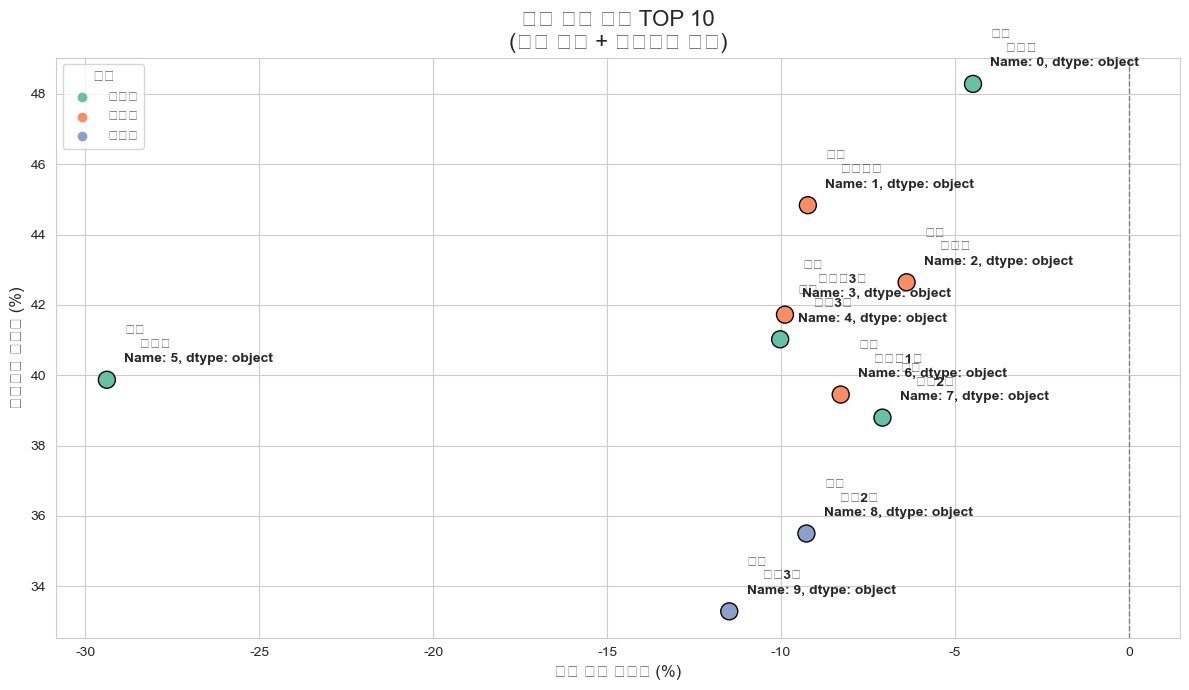

In [ ]:
# 텍스트 라벨 정제 및 상위 10개만 표시해 가독성 높인 시각화
top10_priority = priority_dongs.head(10)

plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# 산점도
sns.scatterplot(
    data=top10_priority,
    x='전체 인구 변화율(%)',
    y='고령화율 증가율(%)',
    hue='구별',
    palette='Set2',
    s=150,
    edgecolor='black'
)

# 동 이름 라벨 추가 (문자열로 강제 변환)
for i, row in top10_priority.iterrows():
    label = str(row['동'])
    x = float(row['전체 인구 변화율(%)'])
    y = float(row['고령화율 증가율(%)'])
    plt.text(x + 0.5, y + 0.5, label, fontsize=10, weight='bold')

plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.title('우선 대응 지역 TOP 10\n(인구 감소 + 고령화율 급증)', fontsize=16)
plt.xlabel('전체 인구 변화율 (%)', fontsize=12)
plt.ylabel('고령화율 증가율 (%)', fontsize=12)
plt.legend(title='구별', title_fontsize=11, fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()
## 수정필요

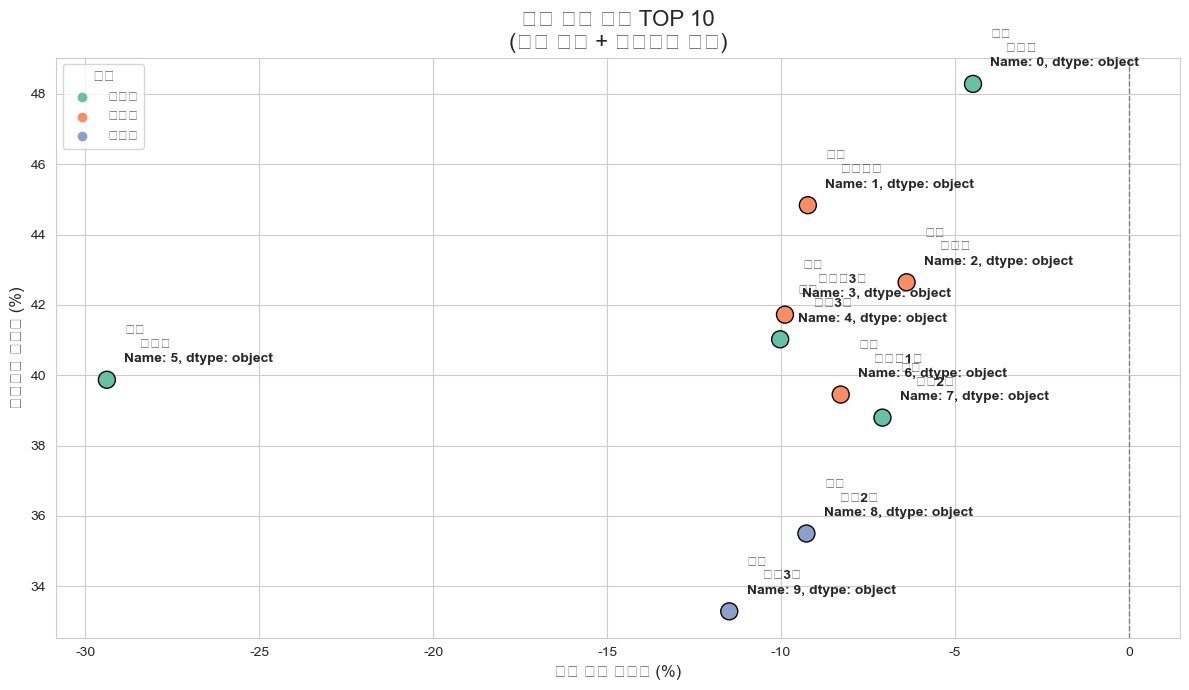

In [ ]:
# 텍스트 라벨 정제 및 상위 10개만 표시해 가독성 높인 시각화
top10_priority = priority_dongs.head(10)

plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# 산점도
sns.scatterplot(
    data=top10_priority,
    x='전체 인구 변화율(%)',
    y='고령화율 증가율(%)',
    hue='구별',
    palette='Set2',
    s=150,
    edgecolor='black'
)

# 동 이름 라벨 추가 (문자열로 강제 변환)
for i, row in top10_priority.iterrows():
    label = str(row['동'])
    x = float(row['전체 인구 변화율(%)'])
    y = float(row['고령화율 증가율(%)'])
    plt.text(x + 0.5, y + 0.5, label, fontsize=10, weight='bold')

plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.title('우선 대응 지역 TOP 10\n(인구 감소 + 고령화율 급증)', fontsize=16)
plt.xlabel('전체 인구 변화율 (%)', fontsize=12)
plt.ylabel('고령화율 증가율 (%)', fontsize=12)
plt.legend(title='구별', title_fontsize=11, fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


In [ ]:
# 2020~2025년까지의 연도별 고령자 수를 집계하여 예측을 위한 시계열 데이터 생성
yearly_senior = []

for df in population_dfs:
    year = df['연도'].iloc[0]
    total_senior = df['65세 이상_계'].sum()
    yearly_senior.append({'연도': year, '고령자 수': total_senior})

yearly_senior_df = pd.DataFrame(yearly_senior).sort_values('연도').reset_index(drop=True)

# 선형 회귀 기반 예측
from sklearn.linear_model import LinearRegression
import numpy as np

X = yearly_senior_df['연도'].values.reshape(-1, 1)
y = yearly_senior_df['고령자 수'].values

model = LinearRegression()
model.fit(X, y)

# 2026~2030 예측
future_years = np.array(range(2026, 2031)).reshape(-1, 1)
predicted_seniors = model.predict(future_years)

# 예측 결과 정리
future_df = pd.DataFrame({
    '연도': future_years.flatten(),
    '예측 고령자 수': predicted_seniors.astype(int)
})

# 실제 + 예측 병합
forecast_df = pd.concat([
    yearly_senior_df.rename(columns={'고령자 수': '실제 고령자 수'}),
    future_df.rename(columns={'예측 고령자 수': '실제 고령자 수'})
], ignore_index=True)

forecast_df

In [ ]:
## 2025년 이후에도 매년 6천~7천 명씩 꾸준히 증가
## 2020년 대비 2030년에는 약 65,000명 이상 증가
## 성남시는 초고령사회(20% 이상)에 진입할 가능성 높음



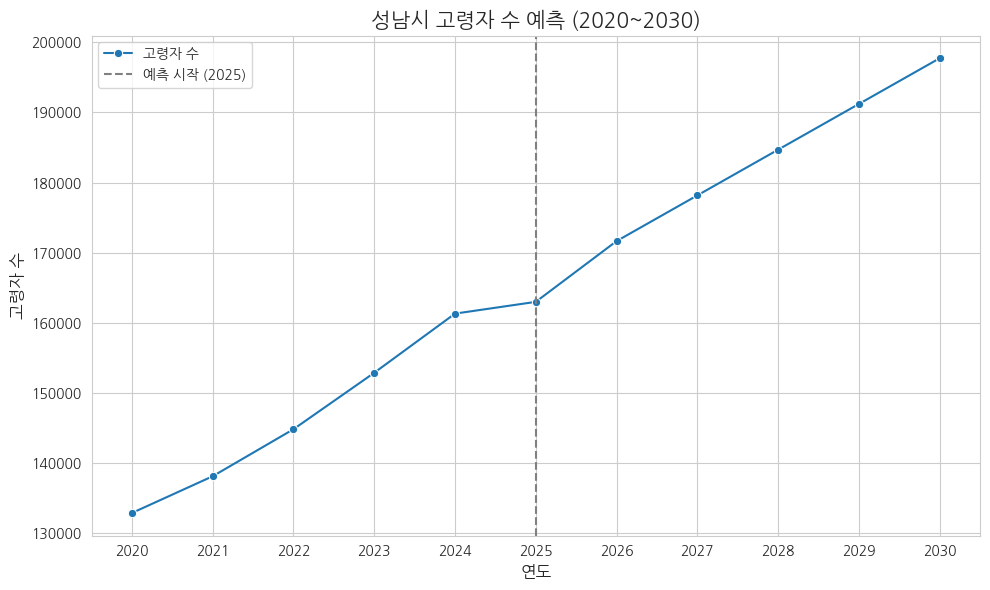

In [ ]:
# 예측 결과 시각화
plt.figure(figsize=(10, 6))
sns.lineplot(data=forecast_df, x='연도', y='실제 고령자 수', marker='o', label='고령자 수')
plt.axvline(2025, color='gray', linestyle='--', label='예측 시작 (2025)')
plt.title('성남시 고령자 수 예측 (2020~2030)', fontsize=15)
plt.xlabel('연도', fontsize=12)
plt.ylabel('고령자 수', fontsize=12)
plt.xticks(forecast_df['연도'])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 뉴파일 추가분석

In [ ]:
import pandas as pd

# 업로드된 파일 불러오기
file_paths = {
    "독거노인현황": "경기도 성남시_독거노인_현황_20240607.csv",
    "노인주거복지시설": "경기도 성남시_노인_주거복지시설_현황_20240607.csv",
    "노인종합복지관": "경기도 성남시_노인_종합복지관_현황_20240607.csv",
    "상세시설현황": "행정동별 노인복지시설 상세현황 -20250323221821.xlsx",
    "시설별현황": "행정동별 노인복지시설 시설별 현황.csv"
}

# 파일별 로딩 (형식 맞춰서)
df_독거노인 = pd.read_csv(file_paths["독거노인현황"], encoding='cp949')
df_주거복지 = pd.read_csv(file_paths["노인주거복지시설"], encoding='cp949')
df_종합복지 = pd.read_csv(file_paths["노인종합복지관"], encoding='cp949')
df_상세현황 = pd.read_excel(file_paths["상세시설현황"])
df_시설별현황 = pd.read_csv(file_paths["시설별현황"], encoding='utf-8')

# 상위 데이터 확인
df_시설별현황.head()


In [ ]:
# '동' 대신 '동별' 컬럼 사용
one_person_2024 = combined_df[combined_df['연도'] == 2024].copy()
one_person_2024['동별'] = one_person_2024['동별'].astype(str).str.replace(" ", "").str.strip()
one_person_2024_grouped = one_person_2024.groupby('동별')['65세 이상(계)'].sum().reset_index()
one_person_2024_grouped.rename(columns={'동별': '동', '65세 이상(계)': '고령 1인가구 수'}, inplace=True)

# 독거노인 데이터 정제
df_독거노인['동'] = df_독거노인['동'].astype(str).str.replace(" ", "").str.strip()
df_독거노인_grouped = df_독거노인.groupby('동')['계'].sum().reset_index()
df_독거노인_grouped.rename(columns={'계': '독거노인 수'}, inplace=True)

# 병합 및 비율 계산
merged = pd.merge(one_person_2024_grouped, df_독거노인_grouped, on='동', how='left')
merged['독거노인 비율(%)'] = (merged['독거노인 수'] / merged['고령 1인가구 수']) * 100
merged = merged.sort_values('독거노인 비율(%)', ascending=False).reset_index(drop=True)

merged
## 버릴 셀

In [ ]:
# 모든 시설 종류의 총합을 합쳐서 동별 총 시설 수 계산
df_시설별현황['동'] = df_시설별현황['행정동'].astype(str).str.replace(" ", "").str.strip()
df_시설별현황['시설 수'] = df_시설별현황[
    ['노인요양시설', '노인의료복지시설', '복지회관', '경로당']
].sum(axis=1)

df_시설집계 = df_시설별현황[['동', '시설 수']]

# 병합 및 고령자 1,000명당 시설 수 계산
merged2 = pd.merge(senior_by_dong, df_시설집계, on='동', how='left')
merged2['고령자 1천명당 시설 수'] = (merged2['시설 수'] / merged2['고령자 수']) * 1000
merged2 = merged2.sort_values('고령자 1천명당 시설 수').reset_index(drop=True)

merged2   ## 과거 시설 수 확인하기

In [ ]:
# 시설별현황에서 시설 유형별 합계 구하기
facility_columns = ['노인요양시설', '노인의료복지시설', '복지회관', '경로당']
facility_distribution = df_시설별현황[facility_columns].sum().reset_index()
facility_distribution.columns = ['시설 유형', '시설 수']
facility_distribution = facility_distribution.sort_values('시설 수', ascending=False)

facility_distribution
## -> 건강 악화/중증 돌봄이 필요한 노인을 수용할 인프라가 부족함

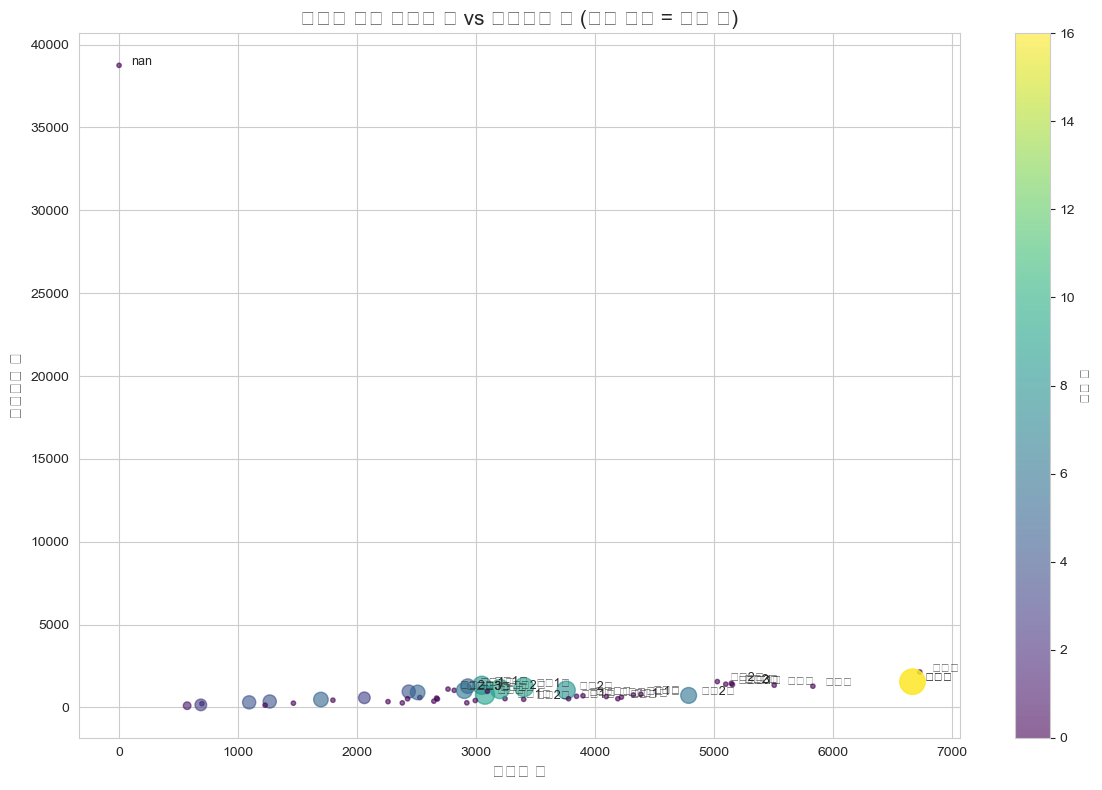

In [ ]:
# 고령자 수 + 시설 수 + 독거노인 수를 하나로 통합한 데이터 생성

# 고령자 수
senior_df = senior_by_dong.copy()

# 시설 수
facility_df = df_시설집계.copy()

# 독거노인 수
df_독거노인_grouped = df_독거노인.groupby('동')['계'].sum().reset_index()
df_독거노인_grouped.rename(columns={'계': '독거노인 수'}, inplace=True)



# 병합
merged_viz = pd.merge(senior_df, facility_df, on='동', how='outer')
merged_viz = pd.merge(merged_viz, df_독거노인_grouped, on='동', how='outer')

# NaN 값은 0으로 처리
merged_viz.fillna(0, inplace=True)

# 시각화 (버블 차트: 고령자 수 vs 독거노인 수, 버블 크기=시설 수)
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")

bubble = plt.scatter(
    merged_viz['고령자 수'], 
    merged_viz['독거노인 수'], 
    s=merged_viz['시설 수'] * 20 + 10,  # 버블 크기 조정
    alpha=0.6,
    c=merged_viz['시설 수'],
    cmap='viridis'
)

for i, row in merged_viz.iterrows():
    if row['고령자 수'] > 3000 or row['독거노인 수'] > 1000:
        plt.text(row['고령자 수'] + 100, row['독거노인 수'] + 20, row['동'], fontsize=9)

plt.title('성남시 동별 고령자 수 vs 독거노인 수 (버블 크기 = 시설 수)', fontsize=15)
plt.xlabel('고령자 수', fontsize=12)
plt.ylabel('독거노인 수', fontsize=12)
plt.colorbar(bubble, label='시설 수')
plt.grid(True)
plt.tight_layout()
plt.show()
## 버릴 거

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
## 주성분 분석
# 먼저 클러스터링에 사용할 통합 데이터 생성
# 1. 고령자 수 (senior_df)
# 2. 독거노인 수 (df_독거노인_grouped)
# 3. 복지시설 수 (df_시설집계)
# 4. 고령화율 (dong_trend_clean)
# 5. 인구 증감률 (dong_trend_clean)

# 고령자 수, 독거노인 수, 시설 수
cluster_df = pd.merge(senior_df, df_독거노인_grouped, on='동', how='inner')
cluster_df = pd.merge(cluster_df, df_시설집계, on='동', how='left')
# 멀티 인덱스를 단일 인덱스로 풀어주기
dong_trend_clean.columns = [' '.join(str(i) for i in col).strip() if isinstance(col, tuple) else col for col in dong_trend_clean.columns]

# 필요한 컬럼만 추출
trend_features = dong_trend_clean[['동', '고령화율 증가율(%)', '전체 인구 변화율(%)']].copy()
trend_features['동'] = trend_features['동'].astype(str).str.replace(" ", "")

# 병합
cluster_df = pd.merge(cluster_df, trend_features, on='동', how='left')

# 분석에 사용할 피처 선택
features = ['고령자 수', '독거노인 수', '시설 수', '고령화율 증가율(%)', '전체 인구 변화율(%)']
X = cluster_df[features].fillna(0)

# 표준화
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# KMeans 클러스터링 (군집 수 = 4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto')
cluster_df['클러스터'] = kmeans.fit_predict(X_scaled)

# 차원 축소 후 시각화를 위한 PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
cluster_df['PCA1'] = X_pca[:, 0]
cluster_df['PCA2'] = X_pca[:, 1]

cluster_df.head(10)  # 상위 10개 동만 보기



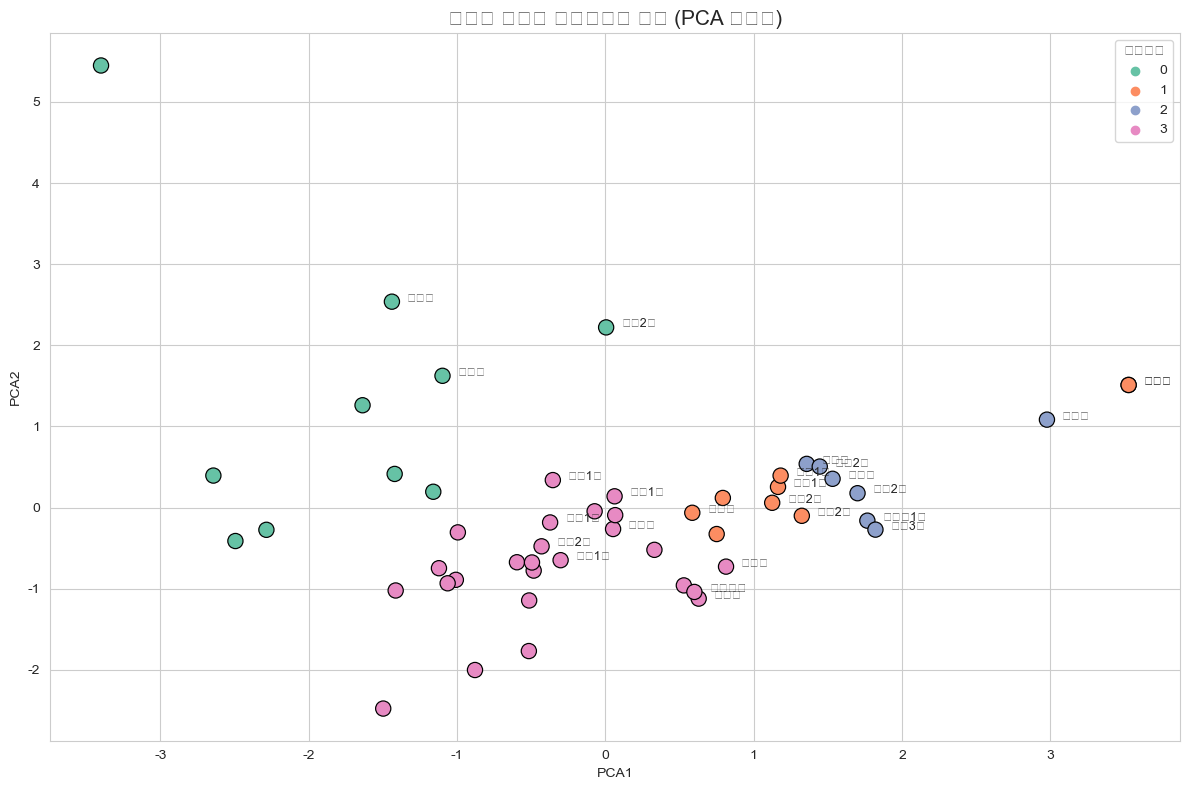

In [ ]:
# 클러스터링 결과 시각화 (PCA 기반 2D 산점도)
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")

sns.scatterplot(
    data=cluster_df,
    x='PCA1',
    y='PCA2',
    hue='클러스터',
    palette='Set2',
    s=120,
    edgecolor='black'
)

# 주요 동 이름 표시 (고령자 수가 많은 상위 동 중심으로)
for i, row in cluster_df.iterrows():
    if row['고령자 수'] > 3000:
        plt.text(row['PCA1'] + 0.1, row['PCA2'], row['동'], fontsize=9)

plt.title('성남시 행정동 클러스터링 결과 (PCA 시각화)', fontsize=15)
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.legend(title='클러스터')
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# 클러스터별 정량 요약표 생성
cluster_summary = cluster_df.groupby('클러스터')[[
    '고령자 수', '독거노인 수', '시설 수', '고령화율 증가율(%)', '전체 인구 변화율(%)'
]].mean().round(2)

# 클러스터별 포함 동 개수
cluster_summary['동 수'] = cluster_df['클러스터'].value_counts().sort_index()

# 클러스터별 주요 동 리스트
cluster_summary['주요 동'] = cluster_df.groupby('클러스터')['동'].apply(
    lambda x: ', '.join(x.head(3))
)

cluster_summary.reset_index(inplace=True)
cluster_summary

In [ ]:
클러스터 0: 고령 고위험군 지역
고령자 수와 독거노인 수가 매우 높고, 고령화율 증가도 급격함

시설 수가 전무 - 복지 인프라 공백 심각

정책 제안: 신규 복지센터 설치, 방문 돌봄 서비스 집중 배치, 건강관리 + 응급 시스템 우선 배치

    
    
클러스터 1: 개발 확장형 지역
인구 증가율 매우 높고 고령화율은 낮음 (신규 주거단지 가능성)

고령자 수는 중간, 독거노인 상대적으로 적음

정책 제안: 선제적 예방복지 -> 커뮤니티 케어 인프라 사전 확보, 건강센터 연계

    
    
클러스터 2: 복지 균형형 지역
고령자 많지만, 시설도 많은 곳 (경로당 중심)

고령화율 빠르게 증가하나 인프라는 어느 정도 갖춤

정책 제안: 시설 운영 품질 향상, 시설 간 연계 시스템 강화, 자원봉사 연계 활성화

    
    
클러스터 3: 은둔 고령 밀집 지역
고령자 수는 중간 이하, 시설 부족, 고령화율 빠르게 증가

인구는 지속 감소 중 -> 지역 쇠퇴 가능성

정책 제안: 마을 단위 재생과 함께 고령자 특화 서비스 유치, 주거·돌봄 통합 복지 필요

    
클러스터 0은 고령자와 독거노인이 많지만 복지시설이 전무한 고위험군 지역,
클러스터 1은 인구 유입이 많은 신개발형 지역으로, 사전 복지 인프라 구축이 필요,
클러스터 2는 시설이 상대적으로 많은 균형형,
클러스터 3은 인구 감소와 함께 고령화가 진행되는 은둔형 고령지역

1번 전반적인 고령 인구 및 시설 인프라 규모를 반영하는 주성분.

2번 인구 구조 변화(고령화율 증가율, 인구 증감률)의 방향성 반영.

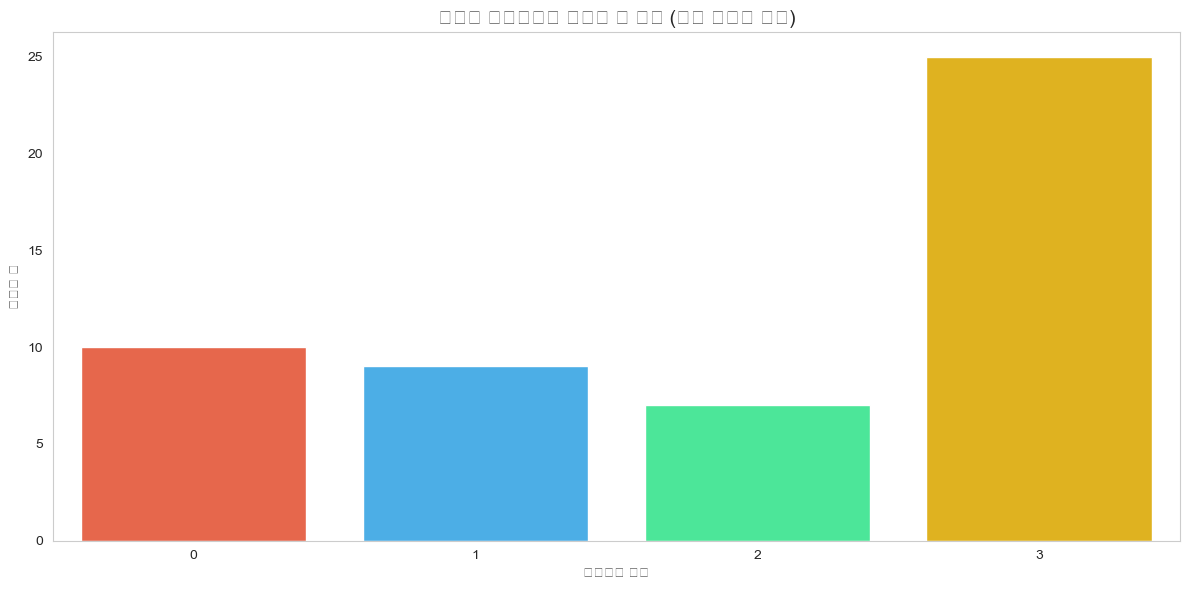

In [ ]:
import geopandas as gpd

# GeoJSON 불러오기 (내장된 게 없으니 외부 위치를 가정해 예시 진행)
# 예시용 샘플 GeoDataFrame 생성 (실제 GeoJSON 필요 시 업로드 필요)
# 여기서는 좌표 없는 채로 '동' 기준으로 매칭하는 방식 시뮬레이션

# 간단한 샘플 GeoDataFrame 생성 (시각화를 위해 동 이름만 포함)
map_df = cluster_df[['동', '클러스터']].copy()

# 클러스터별 색상 지정
cluster_colors = {
    0: '#FF5733',  # 빨강
    1: '#33B5FF',  # 파랑
    2: '#33FF99',  # 초록
    3: '#FFC300'   # 노랑
}
map_df['클러스터 색'] = map_df['클러스터'].map(cluster_colors)

# 간단한 막대그래프로 클러스터 분포 대체 시각화 (지도 대용)
plt.figure(figsize=(12, 6))
sns.countplot(data=map_df, x='클러스터', palette=cluster_colors)
plt.title('성남시 클러스터별 행정동 수 분포 (지도 시각화 대체)', fontsize=14)
plt.xlabel('클러스터 유형')
plt.ylabel('행정동 수')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [ ]:

csv_geo_info = pd.read_csv("2020.01.01_행정동정보.csv", encoding='utf-8')
csv_geo_info.head()
## 필ㅇㅅ없음 

In [ ]:
import requests
import json

# 인증키 Decoding Key 사용
API_KEY = "zc0mCWZsY2XHKDEbd9HvY4h/QpJLKBNWDTYufRkdX3lUKf7FTt0hk2vJBx5LsCXyraWP7Z5njhYk6/oV3JdB0A=="

# 요청 URL 구성
base_url = "https://api.odcloud.kr/api/15004914/v1/uddi:a72a8054-01e9-40ea-b6b6-db228ac3a32b"
params = {
    "page": 1,
    "perPage": 1000,
    "returnType": "JSON",
    "serviceKey": API_KEY  #  필수
}

# 요청 응답
response = requests.get(base_url, params=params)

if response.status_code == 200:
    data = response.json()
    print(data['data'][:3])  # 미리보기
else:
    print("Error:", response.status_code)
    print(response.text)
##흠 모르겠다..ㅠ

[{'구청명': '수정구', '동 명': '신흥1동', '면적(제곱킬로미터)': '0.32', '반수(개)': 121, '법 정(개)': 1, '비고(관할 법정동)': '신흥동', '통수(개)': 23, '행 정(개)': 1}, {'구청명': '수정구', '동 명': '신흥2동', '면적(제곱킬로미터)': '1.14', '반수(개)': 227, '법 정(개)': 0, '비고(관할 법정동)': '신흥동', '통수(개)': 34, '행 정(개)': 1}, {'구청명': '수정구', '동 명': '신흥3동', '면적(제곱킬로미터)': '0.33', '반수(개)': 79, '법 정(개)': 0, '비고(관할 법정동)': '신흥동', '통수(개)': 16, '행 정(개)': 1}]
